In [1]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import torch
import torch.nn as nn

In [42]:
import os
for dirname, _, filenames in os.walk('C:/Users/Tharunraj_S/Desktop/Mini_project/Codes'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

C:/Users/Tharunraj_S/Desktop/Mini_project/Codes\BioMarkers.ipynb
C:/Users/Tharunraj_S/Desktop/Mini_project/Codes\fusion.ipynb
C:/Users/Tharunraj_S/Desktop/Mini_project/Codes\kidney_disease.csv
C:/Users/Tharunraj_S/Desktop/Mini_project/Codes\pytorch_predict.ipynb
C:/Users/Tharunraj_S/Desktop/Mini_project/Codes\Pytorch_train.ipynb
C:/Users/Tharunraj_S/Desktop/Mini_project/Codes\test.csv
C:/Users/Tharunraj_S/Desktop/Mini_project/Codes\trained_model.pt
C:/Users/Tharunraj_S/Desktop/Mini_project/Codes\.ipynb_checkpoints\fusion-checkpoint.ipynb
C:/Users/Tharunraj_S/Desktop/Mini_project/Codes\.ipynb_checkpoints\pytorch_predict-checkpoint.ipynb
C:/Users/Tharunraj_S/Desktop/Mini_project/Codes\.ipynb_checkpoints\Pytorch_train-checkpoint.ipynb


In [43]:
Data="C:/Users/Tharunraj_S/Desktop/Mini_project/Codes\kidney_disease.csv"
df=pd.read_csv(Data)
df.head()

,id,age,bp,sg,al,su,rbc,pc,pcc,ba,...,pcv,wc,rc,htn,dm,cad,appet,pe,ane,classification
0,0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,...,44,7800,5.2,yes,yes,no,good,no,no,ckd
1,1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,...,38,6000,NaN,no,no,no,good,no,no,ckd
2,2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,...,31,7500,NaN,no,yes,no,poor,no,yes,ckd
3,3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,...,32,6700,3.9,yes,no,no,poor,yes,yes,ckd
4,4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,...,35,7300,4.6,no,no,no,good,no,no,ckd


In [4]:
# dropping id column
df.drop('id', axis = 1, inplace = True)

In [5]:
# rename column names to make it more meaningful
df.columns = ['age', 'blood_pressure', 'specific_gravity', 'albumin', 'sugar', 'red_blood_cells', 'pus_cell',
              'pus_cell_clumps', 'bacteria', 'blood_glucose_random', 'blood_urea', 'serum_creatinine', 'sodium',
              'potassium', 'haemoglobin', 'packed_cell_volume', 'white_blood_cell_count', 'red_blood_cell_count',
              'hypertension', 'diabetes_mellitus', 'coronary_artery_disease', 'appetite', 'peda_edema',
              'aanemia', 'class']

In [6]:
df.describe()

,age,blood_pressure,specific_gravity,albumin,sugar,blood_glucose_random,blood_urea,serum_creatinine,sodium,potassium,haemoglobin
count,391.000000,388.000000,353.000000,354.000000,351.000000,356.000000,381.000000,383.000000,313.000000,312.000000,348.000000
mean,51.483376,76.469072,1.017408,1.016949,0.450142,148.036517,57.425722,3.072454,137.528754,4.627244,12.526437
std,17.169714,13.683637,0.005717,1.352679,1.099191,79.281714,50.503006,5.741126,10.408752,3.193904,2.912587
min,2.000000,50.000000,1.005000,0.000000,0.000000,22.000000,1.500000,0.400000,4.500000,2.500000,3.100000
25%,42.000000,70.000000,1.010000,0.000000,0.000000,99.000000,27.000000,0.900000,135.000000,3.800000,10.300000
50%,55.000000,80.000000,1.020000,0.000000,0.000000,121.000000,42.000000,1.300000,138.000000,4.400000,12.650000
75%,64.500000,80.000000,1.020000,2.000000,0.000000,163.000000,66.000000,2.800000,142.000000,4.900000,15.000000
max,90.000000,180.000000,1.025000,5.000000,5.000000,490.000000,391.000000,76.000000,163.000000,47.000000,17.800000


In [7]:
# replace some incorrect values
df['diabetes_mellitus'].replace(to_replace = {'\tno':'no','\tyes':'yes',' yes':'yes'},inplace=True)

df['coronary_artery_disease'] = df['coronary_artery_disease'].replace(to_replace = '\tno', value='no')

df['class'] = df['class'].replace(to_replace = {'ckd\t': 'ckd', 'notckd': 'not ckd'})

In [8]:
# converting necessary columns to numerical type
df['packed_cell_volume'] = pd.to_numeric(df['packed_cell_volume'], errors='coerce')
df['white_blood_cell_count'] = pd.to_numeric(df['white_blood_cell_count'], errors='coerce')
df['red_blood_cell_count'] = pd.to_numeric(df['red_blood_cell_count'], errors='coerce')

In [9]:
df['class'] = df['class'].map({'not ckd': 0, 'ckd': 1})
df['class'] = pd.to_numeric(df['class'], errors='coerce')

In [10]:
# Extracting categorical and numerical columns
cat_cols = [col for col in df.columns if df[col].dtype == 'object']
num_cols = [col for col in df.columns if df[col].dtype != 'object']

In [11]:
df.head(10)

,age,blood_pressure,specific_gravity,albumin,sugar,red_blood_cells,pus_cell,pus_cell_clumps,bacteria,blood_glucose_random,...,packed_cell_volume,white_blood_cell_count,red_blood_cell_count,hypertension,diabetes_mellitus,coronary_artery_disease,appetite,peda_edema,aanemia,class
0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,121.0,...,44.0,7800.0,5.2,yes,yes,no,good,no,no,1
1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,NaN,...,38.0,6000.0,NaN,no,no,no,good,no,no,1
2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,423.0,...,31.0,7500.0,NaN,no,yes,no,poor,no,yes,1
3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,117.0,...,32.0,6700.0,3.9,yes,no,no,poor,yes,yes,1
4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,106.0,...,35.0,7300.0,4.6,no,no,no,good,no,no,1
5,60.0,90.0,1.015,3.0,0.0,NaN,NaN,notpresent,notpresent,74.0,...,39.0,7800.0,4.4,yes,yes,no,good,yes,no,1
6,68.0,70.0,1.010,0.0,0.0,NaN,normal,notpresent,notpresent,100.0,...,36.0,NaN,NaN,no,no,no,good,no,no,1
7,24.0,NaN,1.015,2.0,4.0,normal,abnormal,notpresent,notpresent,410.0,...,44.0,6900.0,5.0,no,yes,no,good,yes,no,1
8,52.0,100.0,1.015,3.0,0.0,normal,abnormal,present,notpresent,138.0,...,33.0,9600.0,4.0,yes,yes,no,good,no,yes,1
9,53.0,90.0,1.020,2.0,0.0,abnormal,abnormal,present,notpresent,70.0,...,29.0,12100.0,3.7,yes,yes,no,poor,no,yes,1


In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 25 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   age                      391 non-null    float64
 1   blood_pressure           388 non-null    float64
 2   specific_gravity         353 non-null    float64
 3   albumin                  354 non-null    float64
 4   sugar                    351 non-null    float64
 5   red_blood_cells          248 non-null    object 
 6   pus_cell                 335 non-null    object 
 7   pus_cell_clumps          396 non-null    object 
 8   bacteria                 396 non-null    object 
 9   blood_glucose_random     356 non-null    float64
 10  blood_urea               381 non-null    float64
 11  serum_creatinine         383 non-null    float64
 12  sodium                   313 non-null    float64
 13  potassium                312 non-null    float64
 14  haemoglobin              3

In [13]:
# filling null values, we will use two methods, random sampling for higher null values and mean/mode sampling for lower null values
def random_value_imputation(feature):
    random_sample = df[feature].dropna().sample(df[feature].isna().sum())
    random_sample.index = df[df[feature].isnull()].index
    df.loc[df[feature].isnull(), feature] = random_sample
    
def impute_mode(feature):
    mode = df[feature].mode()[0]
    df[feature] = df[feature].fillna(mode)

In [14]:
# filling num_cols null values using random sampling method
for col in num_cols:
    random_value_imputation(col)
    
df[num_cols].isnull().sum()

age                       0
blood_pressure            0
specific_gravity          0
albumin                   0
sugar                     0
blood_glucose_random      0
blood_urea                0
serum_creatinine          0
sodium                    0
potassium                 0
haemoglobin               0
packed_cell_volume        0
white_blood_cell_count    0
red_blood_cell_count      0
class                     0
dtype: int64

In [15]:
# filling "red_blood_cells" and "pus_cell" using random sampling method and rest of cat_cols using mode imputation
random_value_imputation('red_blood_cells')
random_value_imputation('pus_cell')

for col in cat_cols:
    impute_mode(col)
    
df[cat_cols].isnull().sum()

red_blood_cells            0
pus_cell                   0
pus_cell_clumps            0
bacteria                   0
hypertension               0
diabetes_mellitus          0
coronary_artery_disease    0
appetite                   0
peda_edema                 0
aanemia                    0
dtype: int64

In [16]:
# Printing unique values in cat_cols
for col in cat_cols:
    print(f"{col} has {df[col].nunique()} categories\n")

red_blood_cells has 2 categories

pus_cell has 2 categories

pus_cell_clumps has 2 categories

bacteria has 2 categories

hypertension has 2 categories

diabetes_mellitus has 2 categories

coronary_artery_disease has 2 categories

appetite has 2 categories

peda_edema has 2 categories

aanemia has 2 categories



In [17]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

for col in cat_cols:
    df[col] = le.fit_transform(df[col])

In [18]:
df.head(10)

,age,blood_pressure,specific_gravity,albumin,sugar,red_blood_cells,pus_cell,pus_cell_clumps,bacteria,blood_glucose_random,...,packed_cell_volume,white_blood_cell_count,red_blood_cell_count,hypertension,diabetes_mellitus,coronary_artery_disease,appetite,peda_edema,aanemia,class
0,48.0,80.0,1.020,1.0,0.0,1,1,0,0,121.0,...,44.0,7800.0,5.2,1,1,0,0,0,0,1
1,7.0,50.0,1.020,4.0,0.0,0,1,0,0,110.0,...,38.0,6000.0,4.0,0,0,0,0,0,0,1
2,62.0,80.0,1.010,2.0,3.0,1,1,0,0,423.0,...,31.0,7500.0,4.2,0,1,0,1,0,1,1
3,48.0,70.0,1.005,4.0,0.0,1,0,1,0,117.0,...,32.0,6700.0,3.9,1,0,0,1,1,1,1
4,51.0,80.0,1.010,2.0,0.0,1,1,0,0,106.0,...,35.0,7300.0,4.6,0,0,0,0,0,0,1
5,60.0,90.0,1.015,3.0,0.0,1,1,0,0,74.0,...,39.0,7800.0,4.4,1,1,0,0,1,0,1
6,68.0,70.0,1.010,0.0,0.0,1,1,0,0,100.0,...,36.0,15700.0,3.9,0,0,0,0,0,0,1
7,24.0,60.0,1.015,2.0,4.0,1,0,0,0,410.0,...,44.0,6900.0,5.0,0,1,0,0,1,0,1
8,52.0,100.0,1.015,3.0,0.0,1,0,1,0,138.0,...,33.0,9600.0,4.0,1,1,0,0,0,1,1
9,53.0,90.0,1.020,2.0,0.0,0,0,1,0,70.0,...,29.0,12100.0,3.7,1,1,0,1,0,1,1


In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 25 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   age                      400 non-null    float64
 1   blood_pressure           400 non-null    float64
 2   specific_gravity         400 non-null    float64
 3   albumin                  400 non-null    float64
 4   sugar                    400 non-null    float64
 5   red_blood_cells          400 non-null    int32  
 6   pus_cell                 400 non-null    int32  
 7   pus_cell_clumps          400 non-null    int32  
 8   bacteria                 400 non-null    int32  
 9   blood_glucose_random     400 non-null    float64
 10  blood_urea               400 non-null    float64
 11  serum_creatinine         400 non-null    float64
 12  sodium                   400 non-null    float64
 13  potassium                400 non-null    float64
 14  haemoglobin              4

In [23]:
from sklearn.model_selection import train_test_split
import numpy as np
# Data normalization
X = df.drop("class", axis=1)
y = df["class"]

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

X_train_array = X_train.to_numpy()  # Convert Series to numpy array
X_test_array = X_test.to_numpy()

y_train_array = y_train.to_numpy()  # Convert Series to numpy array
y_test_array = y_test.to_numpy()


# Convert to PyTorch tensors
X_train_tensor = torch.tensor(X_train_array, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_array, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train_array, dtype=torch.long)
y_test_tensor = torch.tensor(y_test_array, dtype=torch.long)


In [24]:
#X_scaled


In [25]:
from torch.utils.data import DataLoader, TensorDataset

# Create a TensorDataset
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)

# Create a DataLoader
batch_size = 64  # Adjust this based on your preferences
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)


In [26]:
from torch.utils.data import DataLoader, TensorDataset

# Create a TensorDataset
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

# Create a DataLoader
batch_size = 64  # Adjust this based on your preferences
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)  # No need to shuffle for evaluation


In [27]:
class KidneyNN(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super(KidneyNN, self).__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(hidden_size, output_size)
    
    def forward(self, x):
        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)
        return x
 

In [36]:
   
input_size = 24 # number of biomarkers
hidden_size = 64 # choose an appropriate value
output_size=num_classes = 2 

model = KidneyNN(input_size, hidden_size, output_size)

criterion = nn.CrossEntropyLoss()  # For classification

optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

num_epochs = 50 # choose an appropriate value


In [37]:
import matplotlib.pyplot as plt

# Initialize an empty list to store loss values for each epoch
epoch_losses = []

for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0

    for inputs, labels in train_loader: 
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()

    # Calculate average loss for the current epoch
    epoch_loss = running_loss / len(train_loader)
    epoch_losses.append(epoch_loss)  # Store the loss for this epoch

    print(f'Epoch [{epoch+1}/{num_epochs}], Loss: {epoch_loss}')




Epoch [1/50], Loss: 107.25646286010742
Epoch [2/50], Loss: 43.892876100540164
Epoch [3/50], Loss: 22.654246520996093
Epoch [4/50], Loss: 24.034672737121582
Epoch [5/50], Loss: 16.089430236816405
Epoch [6/50], Loss: 11.893272399902344
Epoch [7/50], Loss: 4.922049808502197
Epoch [8/50], Loss: 6.51130530834198
Epoch [9/50], Loss: 3.5743855476379394
Epoch [10/50], Loss: 2.5928640842437742
Epoch [11/50], Loss: 2.612135815620422
Epoch [12/50], Loss: 4.007306528091431
Epoch [13/50], Loss: 4.291461324691772
Epoch [14/50], Loss: 3.843319463729858
Epoch [15/50], Loss: 3.5198678016662597
Epoch [16/50], Loss: 2.929598069190979
Epoch [17/50], Loss: 5.321532666683197
Epoch [18/50], Loss: 4.345843267440796
Epoch [19/50], Loss: 2.255470633506775
Epoch [20/50], Loss: 4.124199295043946
Epoch [21/50], Loss: 3.4874748647212983
Epoch [22/50], Loss: 5.53970422744751
Epoch [23/50], Loss: 4.194996774196625
Epoch [24/50], Loss: 2.4013477206230163
Epoch [25/50], Loss: 1.6597972512245178
Epoch [26/50], Loss: 1.8

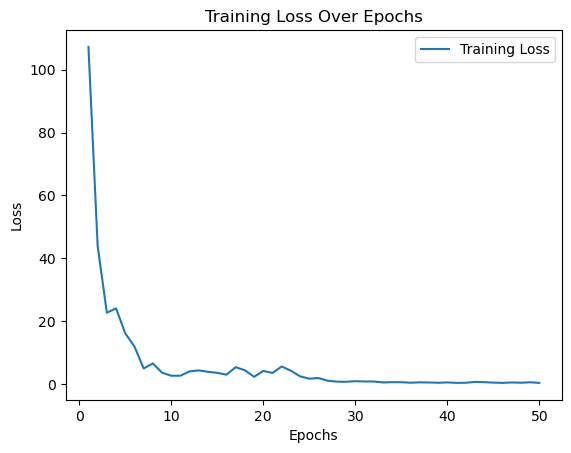

In [38]:
# Plot the loss graph after training is completed
plt.plot(range(1, num_epochs+1), epoch_losses, label='Training Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training Loss Over Epochs')
plt.legend()
plt.show()

In [39]:
from sklearn.metrics import classification_report

with torch.no_grad():
    all_predictions = []
    all_labels = []
    for inputs, labels in test_loader:
        outputs = model(inputs)
        _, predicted = torch.max(outputs, 1)
        all_predictions.extend(predicted.tolist())
        all_labels.extend(labels.tolist())

report = classification_report(all_labels, all_predictions)
print(report)


              precision    recall  f1-score   support

           0       0.93      0.96      0.95        28
           1       0.98      0.96      0.97        52

    accuracy                           0.96        80
   macro avg       0.96      0.96      0.96        80
weighted avg       0.96      0.96      0.96        80



In [40]:
model.eval()  # Set model to evaluation mode
total_correct = 0
total_samples = 0

with torch.no_grad():
    for inputs, labels in test_loader:
        outputs = model(inputs)
        _, predicted = torch.max(outputs, 1)
        total_samples += labels.size(0)
        total_correct += (predicted == labels).sum().item()

accuracy = total_correct / total_samples
print(f'Accuracy on the test set: {accuracy * 100:.2f}%')


Accuracy on the test set: 96.25%


In [44]:
# Save the model to a file
model_path = 'trained_model.pt'
torch.save(model.state_dict(), model_path)

print(f'Model saved to {model_path}')


Model saved to trained_model.pt


In [ ]:
'''# Load the model from the file
loaded_model = KidneyNN(input_size, hidden_size, num_classes)  # Recreate the model architecture
loaded_model.load_state_dict(torch.load(model_path))
loaded_model.eval()  # Set the model to evaluation mode

print('Model loaded successfully')
'''